# Face Clustering · K-means and DBSCAN

## Installing face-recognition library

In [ ]:
!pip3 install face_recognition

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566170 sha256=b61b826c4cdbbaec21d621735a6ac1c160d2ad88656c4873f18a4b938f9cd866
  Stored in directory: /root/.cache/pip/wheels/7a/eb/cf/e9eced74122b679557f597bb7c8e4c739cfcac526db1fd523d
Successfully built face-recognition-models


## Importing required libraries

In [1]:
import os
import pickle
import numpy as np
import cv2

from PIL import Image
from imutils import paths, build_montages
from sklearn.cluster import KMeans, DBSCAN
import face_recognition

## Demo to test face-recognition in Colab

array([[[ 95, 107, 132],
        [ 95, 107, 132],
        [ 95, 107, 132],
        ...,
        [ 37,  50,  66],
        [ 40,  53,  69],
        [ 39,  52,  68]],

       [[ 95, 107, 132],
        [ 95, 107, 132],
        [ 95, 107, 132],
        ...,
        [ 38,  51,  67],
        [ 38,  51,  67],
        [ 37,  50,  66]],

       [[ 96, 108, 133],
        [ 96, 108, 133],
        [ 96, 108, 133],
        ...,
        [ 38,  51,  67],
        [ 38,  51,  67],
        [ 38,  51,  67]],

       ...,

       [[ 94, 119,  47],
        [ 95, 120,  50],
        [ 95, 120,  52],
        ...,
        [ 82, 107,  23],
        [ 82, 107,  23],
        [ 82, 107,  23]],

       [[ 91, 116,  44],
        [ 95, 120,  50],
        [ 99, 123,  56],
        ...,
        [ 83, 106,  23],
        [ 83, 106,  23],
        [ 82, 105,  22]],

       [[ 87, 112,  40],
        [ 96, 121,  51],
        [105, 129,  62],
        ...,
        [ 82, 105,  22],
        [ 82, 105,  22],
        [ 82, 105,  22]]

I found 1 face(s) in this photograph.
A face is located at pixel location Top: 39, Left: 398, Bottom: 101, Right: 460


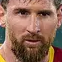

In [3]:
# Path to image
image = face_recognition.load_image_file("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/messi.jpg")
face_locations = face_recognition.face_locations(image)

display(image)

print("I found {} face(s) in this photograph.".format(len(face_locations)))

for face_location in face_locations:

    # Print the location of each face in this image
    top, right, bottom, left = face_location
    print("A face is located at pixel location Top: {}, Left: {}, Bottom: {}, Right: {}".format(top, left, bottom, right))

    # You can access the actual face itself like this:
    face_image = image[top:bottom, left:right]
    pil_image = Image.fromarray(face_image)
    display(pil_image)

## Creating encodings for the dataset

In [4]:
# Specify paths
dataset_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset"
encodings_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/encodings.pickle"

# Initialize variables
data = []

# Get image paths from the dataset directory
imagePaths = list(paths.list_images(dataset_path))

# Loop over the image paths
for (i, imagePath) in enumerate(imagePaths):
    print("[INFO] processing image {}/{}".format(i + 1, len(imagePaths)))
    print(imagePath)

    # Read the image
    image = cv2.imread(imagePath)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Detect faces
    boxes = face_recognition.face_locations(image)

    # Compute facial encodings
    encodings = face_recognition.face_encodings(image, boxes)

    # Build dictionary
    d = [{"imagePath": imagePath, "loc": box, "encoding": enc}
         for (box, enc) in zip(boxes, encodings)]
    data.extend(d)

# Save encodings to file
with open(encodings_path, "wb") as f:
    pickle.dump(data, f)

print("Encodings of images saved in {}".format(encodings_path))


[INFO] processing image 1/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000000.jpg
[INFO] processing image 2/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000001.jpg
[INFO] processing image 3/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000002.jpg
[INFO] processing image 4/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000003.jpg
[INFO] processing image 5/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000004.jpg
[INFO] processing image 6/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000005.jpg
[INFO] processing image 7/129
C:/Users/samik/OneDrive/Desk

## Clustering with K-means

In [5]:
# Specify paths
ENCODINGS_PATH = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/encodings.pickle"
CLUSTERING_RESULT_PATH = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/KNN_Clustering_Result"

# Create Clustering Results directory if it doesn't exist
if not os.path.exists(CLUSTERING_RESULT_PATH):
    os.mkdir(CLUSTERING_RESULT_PATH)

# Load encodings
print("[INFO] loading encodings...")
data = pickle.load(open(ENCODINGS_PATH, "rb"))
data = np.array(data)
encodings = [d["encoding"] for d in data]

# Convert encodings to numpy array
encodings = np.array(encodings)

# Perform KMeans clustering
print("[INFO] clustering...")
kmeans = KMeans(n_clusters=5)  # You can adjust the number of clusters
labels = kmeans.fit_predict(encodings)

# Determine unique label IDs
labelIDs = np.unique(labels)
numUniqueFaces = len(np.where(labelIDs > -1)[0])
print("[INFO] # unique faces: {}".format(numUniqueFaces))

# Loop over unique label IDs
for labelID in labelIDs:
    print("[INFO] faces for cluster: {}".format(labelID))
    idxs = np.where(labels == labelID)[0]
    idxs = np.random.choice(idxs, size=min(25, len(idxs)), replace=False)

    # Initialize list of faces
    faces = []

    # Loop over sampled indexes
    for i in idxs:
        image = cv2.imread(data[i]["imagePath"])
        (top, right, bottom, left) = data[i]["loc"]
        face = image[top:bottom, left:right]

        # Resize face and add to faces list
        face = cv2.resize(face, (96, 96))
        faces.append(face)

    # Create montage
    montage = build_montages(faces, (96, 96), (5, 5))[0]

    # Save the output montage
    title = "Cluster_{}".format(labelID)
    cv2.imwrite(os.path.join(CLUSTERING_RESULT_PATH, title+'.jpg'), montage)

print("Clustering results saved in {}".format(CLUSTERING_RESULT_PATH))

[INFO] loading encodings...
[INFO] clustering...
[INFO] # unique faces: 5
[INFO] faces for cluster: 0
[INFO] faces for cluster: 1
[INFO] faces for cluster: 2
[INFO] faces for cluster: 3
[INFO] faces for cluster: 4
Clustering results saved in C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/KNN_Clustering_Result


## Saving the K-means model

In [7]:
# Save the KMeans model to a file
model_save_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl"
with open(model_save_path, "wb") as f:
    pickle.dump(kmeans, f)

print(f"KMeans model saved to {model_save_path}")


KMeans model saved to C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl


## Making predictions with the K-means model

In [13]:
# Load the saved KMeans model
model_load_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl"
with open(model_load_path, "rb") as f:
    kmeans = pickle.load(f)

def get_face_encoding(image_path):
    # Load the image using face_recognition
    image = face_recognition.load_image_file(image_path)

    # Find the face locations and encodings in the image
    face_locations = face_recognition.face_locations(image)
    face_encodings = face_recognition.face_encodings(image, face_locations)

    if len(face_encodings) > 0:
        return face_encodings[0]  # Return the first face encoding
    else:
        print("No face found in the image.")
        return None

def predict_cluster(image_path, kmeans_model):
    # Get the encoding for the new image
    encoding = get_face_encoding(image_path)

    if encoding is not None:
        # Predict the cluster for the new encoding using the loaded KMeans model
        cluster_label = kmeans_model.predict([encoding])
        return cluster_label[0]
    else:
        return None

# Path to the new image you want to classify
new_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/download.jpg"

# Predict the cluster for the new image
cluster_label = predict_cluster(new_image_path, kmeans)

if cluster_label is not None:
    print(f"The new image belongs to cluster: {cluster_label}")
else:
    print("Cluster prediction failed.")


The new image belongs to cluster: 2


## Using DBSCAN instead of K-means

In [14]:
# Specify paths
ENCODINGS_PATH = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/encodings.pickle"
CLUSTERING_RESULT_PATH = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/DBSCAN_Clustering_Results"

# Create Clustering Results directory if it doesn't exist
if not os.path.exists(CLUSTERING_RESULT_PATH):
    os.mkdir(CLUSTERING_RESULT_PATH)

# Load encodings
print("[INFO] loading encodings...")
data = pickle.load(open(ENCODINGS_PATH, "rb"))
data = np.array(data)
encodings = [d["encoding"] for d in data]

# Cluster the embeddings
print("[INFO] clustering...")
clt = DBSCAN(metric="euclidean", n_jobs=-1)
clt.fit(encodings)

# Determine unique label IDs
labelIDs = np.unique(clt.labels_)
numUniqueFaces = len(np.where(labelIDs > -1)[0])
print("[INFO] # unique faces: {}".format(numUniqueFaces))

# Loop over unique face integers
for labelID in labelIDs:
    print("[INFO] faces for face ID: {}".format(labelID))
    idxs = np.where(clt.labels_ == labelID)[0]
    idxs = np.random.choice(idxs, size=min(25, len(idxs)), replace=False)

    # Initialize list of faces
    faces = []

    # Loop over sampled indexes
    for i in idxs:
        image = cv2.imread(data[i]["imagePath"])
        (top, right, bottom, left) = data[i]["loc"]
        face = image[top:bottom, left:right]

        # Resize face and add to faces list
        face = cv2.resize(face, (96, 96))
        faces.append(face)

    # Create montage
    montage = build_montages(faces, (96, 96), (5, 5))[0]

    # Save the output montage
    title = "Face_ID_{}".format(labelID)
    title = "Unknown_Faces" if labelID == -1 else title
    cv2.imwrite(os.path.join(CLUSTERING_RESULT_PATH, title+'.jpg'), montage)

print("Clustering results saved in {}".format(CLUSTERING_RESULT_PATH))


[INFO] loading encodings...
[INFO] clustering...
[INFO] # unique faces: 4
[INFO] faces for face ID: -1
[INFO] faces for face ID: 0
[INFO] faces for face ID: 1
[INFO] faces for face ID: 2
[INFO] faces for face ID: 3
Clustering results saved in C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/DBSCAN_Clustering_Results


## Saving DBSCAN model

In [15]:
# Save the DBSCAN model to a file
dbscan_model_save_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/dbscan_model.pkl"
with open(dbscan_model_save_path, "wb") as f:
    pickle.dump(clt, f)

print(f"DBSCAN model saved to {dbscan_model_save_path}")


DBSCAN model saved to C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/dbscan_model.pkl


## Predictions with DBSCAN model

In [17]:
# Load the saved DBSCAN model
dbscan_model_load_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/dbscan_model.pkl"
with open(dbscan_model_load_path, "rb") as f:
    clt = pickle.load(f)

def predict_cluster(image_path, dbscan_model):
    # Get the encoding for the new image
    encoding = get_face_encoding(image_path)

    if encoding is not None:
        # Predict the cluster for the new encoding using the loaded DBSCAN model
        cluster_label = dbscan_model.fit_predict([encoding])
        return cluster_label[0]
    else:
        return None

# Path to the new image you want to classify
new_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/download.jpg"

# Predict the cluster for the new image
cluster_label = predict_cluster(new_image_path, clt)

if cluster_label is not None:
    print(f"The new image belongs to cluster: {cluster_label}")
else:
    print("Cluster prediction failed.")


The new image belongs to cluster: -1


In [ ]:
import face_recognition
import pickle
import numpy as np
from tensorflow.keras.models import model_from_json
import json

# Load the emotion detection CNN model
with open("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotion_model.json", "r") as json_file:
    loaded_model_json = json.load(json_file)

emotion_model = model_from_json(json.dumps(loaded_model_json))  # Pass the loaded dictionary as a string to model_from_json

# load weights into new model
emotion_model.load_weights("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotions_model.weights.h5")
print("Loaded the emotion detection model")

# Load the saved KMeans model
model_load_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl"
with open(model_load_path, "rb") as f:
    kmeans = pickle.load(f)

def get_emotion_labels(image_path):
    # Load the image using face_recognition
    image = face_recognition.load_image_file(image_path)

    # Find the face locations and encodings in the image
    face_locations = face_recognition.face_locations(image)
    face_emotions = []

    for face_location in face_locations:
        # Crop the face from the image
        top, right, bottom, left = face_location
        face_image = image[top:bottom, left:right]

        # Preprocess the face image for emotion detection
        preprocessed_face = preprocess_image(face_image)

        # Predict emotions using your CNN model
        emotion_scores = emotion_model.predict(preprocessed_face)

        # Convert scores to emotion labels
        emotion_label = np.argmax(emotion_scores)
        face_emotions.append(emotion_label)

    return face_emotions

def predict_cluster(image_path, kmeans_model):
    # Get the emotion labels for faces in the image
    emotion_labels = get_emotion_labels(image_path)

    if emotion_labels:
        # Predict the cluster for the emotion labels using the loaded KMeans model
        cluster_label = kmeans_model.predict([emotion_labels])
        return cluster_label[0]
    else:
        return None

# Path to the new image you want to classify
new_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/download.jpg"

# Predict the cluster for the new image
cluster_label = predict_cluster(new_image_path, kmeans)

if cluster_label is not None:
    print(f"The new image belongs to cluster: {cluster_label}")
else:
    print("Cluster prediction failed.")
